# Penalized regression and REML smoothing

`gam_refit` takes the terms of a boosted additive model and fits them once
more as a single penalized regression, with one smoothing parameter per
penalty chosen by restricted maximum likelihood (REML). In practice, boosting
decides which terms enter the model and the refit decides how smooth each of
them is: it returns each term's effective degrees of freedom, its smoothing
parameter, and a pointwise confidence band for its effect. The construction
is the one mgcv uses for `gam(method = "REML")` {cite}`wood2011fast,wood2017generalized`.
The full workflow, with more families and terms, is in
[](../usage/refit.ipynb). Symbols follow
[](../appendix/notation.ipynb): $X$ is a design matrix, $K$ a penalty matrix,
$\lambda$ a smoothing parameter, $W$ a diagonal matrix of weights.

## A first example

The example used throughout the chapter has 300 observations of
$y = \sin(2\pi x) + \varepsilon$, $\varepsilon \sim N(0, 0.3^2)$, with $x$
uniform on $[0, 1]$. We fit a boosted model with one P-spline term, let
`tune_mstop` choose the number of iterations by cross-validation, and refit
the term by REML.

In [1]:
import altair as alt
import numpy as np
import polars as pl

import mboostrs as mb

rng = np.random.default_rng(1)
n = 300
x = rng.uniform(0, 1, n)
y = np.sin(2 * np.pi * x) + rng.normal(0, 0.3, n)
data = {"x": x, "y": y}

tuned = mb.tune_mstop("y ~ bbs(x)", data)
refit = mb.gam_refit(tuned.model)
{"edf": round(refit.edf["bbs(x)"], 2),
 "lambda": round(refit.smoothing["bbs(x)"], 2),
 "sigma": round(refit.sigma, 3)}

{'edf': 8.49, 'lambda': 5.36, 'sigma': 0.292}

The refit reports three numbers that the rest of the chapter derives. The
term uses {eval}`round(refit.edf["bbs(x)"], 2)` effective degrees of
freedom (§8), a curve with that many free parameters beyond the intercept.
Its smoothing parameter $\lambda$ = {eval}`round(refit.smoothing["bbs(x)"], 2)`
is the minimizer of the REML criterion (§5), found by Newton's method
(§6). The residual standard deviation is {eval}`round(refit.sigma, 3)`,
against the simulated 0.3 (§5).

[](../usage/refit.ipynb) shows how to use the refit in an analysis:
effects with intervals and how to plot them, predictions for new rows and new
groups, the corrected intervals, the other response families and
distributional models, and the same calls in R.

## 1 Boosting as shrinkage

Consider L2 boosting with a single base learner that is a linear smoother
$S$, such as a P-spline with a fixed $\lambda$, and step length $\nu$. Each
iteration fits $S$ to the current residuals and adds $\nu$ times the fit, so
after $m$ iterations the fitted values are {cite}`buhlmann2003boosting`

$$
\hat{y}_m = \big[I - (I - \nu S)^m\big]\, y .
$$

With $\nu = 1$ and $m = 2$ this is Tukey's twicing {cite}`tukey1977exploratory`:
fit the smoother to the data, fit the same smoother to the residuals
$y - Sy$, and add the two fits, $Sy + S(y - Sy)$. In the eigenbasis of $S$,
a direction with eigenvalue $s \in [0, 1]$ is multiplied by
$1 - (1 - \nu s)^m$. Directions the smoother reproduces ($s$ near 1, such as
the constant and the straight line for a second-order difference penalty) are
fitted after a few iterations; directions it damps (small $s$) stay shrunk
towards zero until $m$ is large. The effective degrees of freedom of the
boosted fit, $\operatorname{tr}[I - (I - \nu S)^m]$, therefore grows with $m$,
and the stopping iteration chosen by cross-validation sets how much the fit
is shrunk.

That amount is chosen for prediction error. It is not the smoothness a
likelihood would choose, and a bootstrap of the boosted fit repeats the same
shrinkage in every resample, which is why its bands are centred on a shrunk
curve. The next cell computes the degrees of freedom along a boosting path for
one `bbs` learner and compares them with those of the REML refit of the same
term.

In [2]:
# The learner's design and difference penalty on these rows.
term = mb.learner_design("bbs(x)", data)
B, K = np.asarray(term.design), np.asarray(term.penalty)

# lambda giving the learner its default 4 degrees of freedom, by bisection
# on log(lambda); the smoother is S = B (B'B + lambda K)^-1 B'.
def smoother(lam):
    return B @ np.linalg.solve(B.T @ B + lam * K, B.T)

lo, hi = -10.0, 15.0
for _ in range(60):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if np.trace(smoother(np.exp(mid))) > 4 else (lo, mid)
S = smoother(np.exp(lo))
s = np.clip(np.linalg.eigvalsh((S + S.T) / 2), 0, 1)

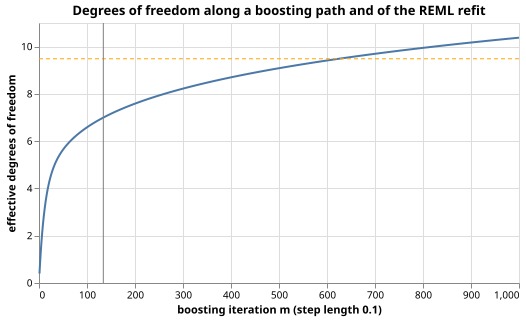

In [3]:
# Degrees of freedom of the boosted fit after m steps of length 0.1.
steps = np.arange(1, 1001)
boost_df = [float(np.sum(1 - (1 - 0.1 * s) ** m)) for m in steps]

# The refit's term edf excludes the intercept, which the boosted fit's trace
# counts; add it back to compare the two.
refit_df = refit.edf["bbs(x)"] + 1
chosen_mstop = tuned.model.mstop
chosen_df = boost_df[chosen_mstop - 1]

path = pl.DataFrame({"iteration": steps, "edf": boost_df})
line = alt.Chart(path).mark_line().encode(
    x=alt.X("iteration").title("boosting iteration m (step length 0.1)"),
    y=alt.Y("edf").title("effective degrees of freedom"),
)
reml = alt.Chart(pl.DataFrame({"edf": [refit_df]})).mark_rule(
    color="orange", strokeDash=[4, 3]).encode(y="edf")
stop = alt.Chart(pl.DataFrame({"iteration": [chosen_mstop]})).mark_rule(
    color="gray").encode(x="iteration")
(line + reml + stop).properties(
    title="Degrees of freedom along a boosting path and of the REML refit",
    width=480, height=260)

The boosted fit's degrees of freedom rise from 1 towards the 4 the learner
was given per step, and beyond, as iterations accumulate. Cross-validation
stopped at $m =$ {eval}`chosen_mstop` (grey line), where the boosted fit uses
{eval}`round(chosen_df, 2)` degrees of freedom. The REML refit of the same
term uses {eval}`round(refit_df, 2)` (orange line, intercept included).

## 2 Penalized least squares

The refit models the response as an intercept plus one smooth function per
term,

$$
y_i = \beta_0 + \sum_{j} f_j(x_{ij}) + \varepsilon_i, \qquad
f_j(x) = X_j(x)\, \beta_j ,
$$

where $X_j$ is the term's basis (B-splines for `bbs`, indicators for
`brandom`, a tensor product for `bspatial`) and $\beta_j$ its coefficients.
Stacking the blocks gives the model matrix $X = [\mathbf{1}, X_1, X_2,
\dots]$ and coefficient vector $\beta$. Each term carries one or more
penalty matrices $K_{jk}$; placed on the term's block of $\beta$ they form
$S_k$, and the total penalty is

$$
S_\lambda = \sum_k \lambda_k S_k .
$$

For a response with weights $W = \operatorname{diag}(w_i)$, the coefficients
minimize the penalized least-squares criterion

$$
\lVert y - X\beta \rVert_W^2 + \beta^\top S_\lambda \beta ,
$$

whose solution is

$$
\hat\beta = A^{-1} X^\top W y, \qquad A = X^\top W X + S_\lambda .
$$

A large $\lambda_k$ forces the penalized part of a term to zero, leaving the
part of the function the penalty does not see: for a second-order difference
penalty that is a straight line, for a ridge penalty (`brandom`) nothing.

## 3 Sum-to-zero constraints

The rows of a B-spline basis sum to one, so every `bbs` term can represent a
constant, and so can the intercept. Without a constraint the model is not
identifiable. The refit requires each term to sum to zero over the fitting
rows, with the prior weights:

$$
\sum_i w_i f_j(x_{ij}) = 0 \iff c_j^\top \beta_j = 0, \qquad c_j = X_j^\top w .
$$

The constraint is imposed by reparametrizing $\beta_j = Z_j \gamma_j$, where
the columns of $Z_j$ span the vectors orthogonal to $c_j$. The refit builds
$Z_j$ from one Householder reflection
$H_j = I - 2 v v^\top / v^\top v$ with $v = c_j - \alpha e_1$ and
$\alpha = -\operatorname{sign}(c_{j1})\lVert c_j \rVert$: $H_j c_j =
\alpha e_1$, so the last $q_j - 1$ columns of $H_j$ are orthogonal to $c_j$
and form $Z_j$. The term's design and penalty become $X_j Z_j$ and
$Z_j^\top K_{jk} Z_j$; only the vector $v$ is stored, and new rows are
constrained by the same reflection. mgcv uses the same construction
{cite}`wood2017generalized`.

The constraint determines what an effect means. A term's effect at $x$ is
its difference from the term's weighted average over the fitting rows, and
its interval is an interval for that centred value. An interval for the
level of the response at $x$ needs the intercept as well, which
`predict` includes.

## 4 The mixed-model view of a penalty

A quadratic penalty can be read as a Gaussian prior. Split each term into the
directions its penalty does not see (the null space: the straight line for a
second-order difference penalty) and the rest (the range space). If the
range-space coefficients are random,

$$
\beta \sim N\!\big(0,\; \phi\, S_\lambda^{-}\big) \quad \text{(range space)},
$$

with $S_\lambda^{-}$ a generalized inverse and $\phi$ the residual variance,
and the null-space coefficients are fixed effects, then the penalized
least-squares estimate is the posterior mode, and for a Gaussian response

$$
\beta \mid y \sim N\!\big(\hat\beta,\; \phi A^{-1}\big).
$$

A smoothing parameter is a ratio of variances: $\lambda_k$ large means the
random part of the term has small variance compared with the noise, so the
term stays close to its null space. Choosing $\lambda$ is choosing variance
components, and the standard way to estimate variance components without the
bias maximum likelihood has when fixed effects are estimated is restricted
maximum likelihood {cite}`patterson1971recovery`.

## 5 The REML criterion

Let $M$ be the dimension of the total penalty's null space (the intercept
and every term's unpenalized directions) and $|S_\lambda|_+$ the product of
the non-zero eigenvalues of $S_\lambda$. The restricted likelihood is the
marginal likelihood of $y$ with the random coefficients integrated out and
an improper flat prior on the fixed ones.

Completing the square in $\beta$,

$$
\lVert y - X\beta \rVert_W^2 + \beta^\top S_\lambda \beta
= P(\lambda) + (\beta - \hat\beta)^\top A (\beta - \hat\beta),
\qquad
P(\lambda) = \lVert y - X\hat\beta \rVert_W^2 + \hat\beta^\top S_\lambda \hat\beta .
$$

The Gaussian integral over $\beta$ contributes
$(2\pi\phi)^{p/2} |A|^{-1/2}$; the prior's normalizing constant contributes
$|S_\lambda|_+^{1/2} (2\pi\phi)^{-(p - M)/2}$; the likelihood contributes
$(2\pi\phi)^{-n/2}$ (with $|W|$ absorbed into a constant). Collecting terms,

$$
-2\, l_r(\lambda, \phi) = \frac{P(\lambda)}{\phi}
+ \log |A| - \log |S_\lambda|_+ + (n - M) \log (2 \pi \phi).
$$

Minimizing over $\phi$ gives $\hat\phi = P(\lambda) / (n - M)$ and, up to a
constant, the criterion the refit minimizes for a Gaussian response:

$$
V(\rho) = (n - M) \log P + \log|A| - \log|S_\lambda|_+,
\qquad \rho_k = \log \lambda_k .
$$

The first term rewards fit: $P$ grows as $\lambda$ grows. The difference
$\log|A| - \log|S_\lambda|_+$ penalizes complexity: as $\lambda_k \to 0$,
$\log|S_\lambda|_+ \to -\infty$ faster than $\log|A|$ falls. The next cell
evaluates $V$ on a grid of $\lambda$ for the one-term model of §1, with the
constraint of §3, and marks the value `gam_refit` returns.

In [4]:
# Constrained design of the term (null space of c' = w'B, unit weights) and
# the model matrix with the intercept.
c = B.sum(axis=0)
Z = np.linalg.qr(c[:, None], mode="complete")[0][:, 1:]
X = np.column_stack([np.ones(n), B @ Z])
Kc = Z.T @ K @ Z
rank = np.linalg.matrix_rank(Kc)
null_dim = X.shape[1] - rank
logdet_K = np.sum(np.log(np.sort(np.linalg.eigvalsh(Kc))[-rank:]))

def reml_criterion(lam):
    S = np.zeros((X.shape[1], X.shape[1]))
    S[1:, 1:] = lam * Kc
    A = X.T @ X + S
    beta = np.linalg.solve(A, X.T @ y)
    P = y @ y - beta @ (X.T @ y)
    logdet_A = np.linalg.slogdet(A)[1]
    return (n - null_dim) * np.log(P) + logdet_A - (rank * np.log(lam) + logdet_K)

grid = np.linspace(-6, 10, 161)
curve = pl.DataFrame({"log_lambda": grid, "V": [reml_criterion(np.exp(g)) for g in grid]})
refit_lambda = refit.smoothing["bbs(x)"]
grid_best = float(grid[np.argmin(curve["V"].to_numpy())])

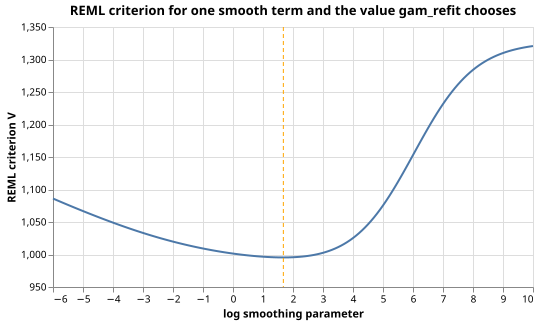

In [5]:
criterion = alt.Chart(curve).mark_line().encode(
    x=alt.X("log_lambda").title("log smoothing parameter"),
    y=alt.Y("V").title("REML criterion V").scale(zero=False),
)
chosen = alt.Chart(pl.DataFrame({"log_lambda": [np.log(refit_lambda)]})).mark_rule(
    color="orange", strokeDash=[4, 3]).encode(x="log_lambda")
(criterion + chosen).properties(
    title="REML criterion for one smooth term and the value gam_refit chooses",
    width=480, height=260)

The criterion has a single minimum on this grid, at $\log\lambda \approx$
{eval}`round(grid_best, 1)`. `gam_refit` returns
$\log\lambda =$ {eval}`round(float(np.log(refit_lambda)), 3)` (orange line),
the same minimum located to full precision by Newton's method.

## 6 Newton's method on the log smoothing parameters

The refit minimizes $V$ over $\rho = \log \lambda$. Working on the log scale
keeps $\lambda$ positive and makes the criterion close to quadratic near its
minimum. Both the gradient and the Hessian are computed exactly
{cite}`wood2011fast`. Since $\hat\beta$ minimizes the penalized criterion,
$\partial \hat\beta / \partial \rho_k = -\lambda_k A^{-1} S_k \hat\beta$, and

$$
\frac{\partial P}{\partial \rho_k} = \lambda_k \hat\beta^\top S_k \hat\beta,
\qquad
\frac{\partial^2 P}{\partial \rho_k \partial \rho_l}
= \delta_{kl} \frac{\partial P}{\partial \rho_k}
- 2 \lambda_k \lambda_l\, \hat\beta^\top S_k A^{-1} S_l \hat\beta,
$$

$$
\frac{\partial \log|A|}{\partial \rho_k} = \lambda_k \operatorname{tr}(A^{-1} S_k),
\qquad
\frac{\partial^2 \log|A|}{\partial \rho_k \partial \rho_l}
= \delta_{kl} \frac{\partial \log|A|}{\partial \rho_k}
- \lambda_k \lambda_l \operatorname{tr}(A^{-1} S_k A^{-1} S_l),
$$

and the same two formulas for $\log|S_\lambda|_+$ on each term's range space.
A single-penalty term has $\log|\lambda_k K|_+ = r \rho_k + \text{const}$, with
$r$ the rank of $K$.

Each Newton step solves $H \delta = -g$ with the Hessian's eigenvalues
replaced by their absolute values (floored at $10^{-7}$ times the largest),
so the step always lowers $V$ to first order. Steps longer than 5 in any
coordinate are shortened, and a step that does not lower $V$ is halved.
Before optimizing, each penalty is rescaled so that its trace equals that of
its term's $X_j^\top W X_j$; $\rho = 0$ is then a balanced starting point for
every term, and $\rho$ is confined to $[-20, 20]$ on that scale. The reported
$\lambda$ is on the scale of the penalty the learner defines.

When a term is best fitted by its null space alone (a straight line for
`bbs`), the minimum is at $\lambda = \infty$. Near that limit
$V \approx c + a e^{-\rho}$, so the gradient and the second derivative have
equal size and Newton's method advances one unit of $\rho$ per iteration. The
refit detects this pattern and tries the bound directly, keeping it only if
$V$ does not rise. For the example of §1 the optimization took
{eval}`refit.convergence["newton_iterations"]` Newton iterations and ended with
gradient norm {eval}`f'{refit.convergence["gradient_norm"]:.1e}'`.

## 7 Tensor-product terms

A two-variable term such as `bspatial(lon, lat)` or `bbs(a) %X% bbs(b)` has a
design whose rows are Kronecker products of the two margins' basis rows, and
two penalties, one per direction:

$$
S_1 = K_a \otimes I_{q_b}, \qquad S_2 = I_{q_a} \otimes K_b .
$$

Each has its own smoothing parameter, so the surface can be smooth in one
variable and wiggly in the other. This is mgcv's `te()` with
`np = FALSE`; mgcv's default `np = TRUE` reparametrizes the margins, which
changes the penalty.

For two penalties on one block the refit diagonalizes them together once.
With $T = P_1 + P_2$ restricted to the block's range space, write
$P_1 = T^{1/2} \tilde{A}\, T^{1/2}$ and $P_2 = T^{1/2} (I - \tilde{A}) T^{1/2}$,
and let $\mu_i \in [0, 1]$ be the eigenvalues of $\tilde{A}$. Then

$$
\log |\lambda_1 P_1 + \lambda_2 P_2| = \log|T|
+ \sum_i \log\big(\lambda_1 \mu_i + \lambda_2 (1 - \mu_i)\big),
$$

which costs $O(r)$ per evaluation after one eigendecomposition, has
closed-form derivatives, and has no cancellation when $\lambda_1$ and
$\lambda_2$ differ by many orders of magnitude. A term with three or more
penalties uses a Cholesky factor of the summed penalty instead.

## 8 Effective degrees of freedom

The matrix $F = A^{-1} X^\top W X$ maps the unpenalized least-squares
estimate $\tilde\beta = (X^\top W X)^{-1} X^\top W y$ to the penalized one,
$\hat\beta = F \tilde\beta$, and $\operatorname{tr}(F)$ equals the trace of
the hat matrix $X A^{-1} X^\top W$: the model's effective degrees of freedom. The
refit reports, for each term, the sum of the diagonal of $F$ over the term's
columns. A direction of the term that the penalty does not see contributes 1,
a fully penalized direction contributes close to 0, so a `bbs` term with a
second-order penalty has edf between 1 (a straight line, after the sum-to-zero
constraint removes the constant) and its number of columns minus one. These
are degrees of freedom of the final fit; the `df` argument of a boosting
learner is the degrees of freedom of one boosting step
([](penalties_df.ipynb)).

## 9 Intervals

The Bayesian posterior of §4 gives the covariance $V_p = \hat\phi A^{-1}$,
and the pointwise interval for a term's effect at $x$ is

$$
\hat f_j(x) \pm z_{1-\alpha/2} \sqrt{X_j(x)\, V_{p,jj}\, X_j(x)^\top} .
$$

These intervals are not confidence intervals at each point. Their average
coverage over the observed $x$ values is close to the nominal level, because
the posterior variance includes a component that accounts for the smoothing
bias {cite}`wahba1983bayesian,nychka1988bayesian`; at a particular point,
such as the top of a peak where the penalty flattens the estimate, coverage
can be lower, and elsewhere higher. {cite:t}`marra2012coverage` show that the
same holds for the components of an additive model when $\lambda$ is chosen
by REML. The next cell measures the average coverage of 90% intervals over
200 simulated samples of the model in §1.

In [6]:
# Average coverage of the 90% interval over 50 points and 200 samples. The
# fitted effect is centred over the sample's rows, so the truth is too.
truth = lambda v: np.sin(2 * np.pi * v)
points = np.linspace(0.02, 0.98, 50)
covered = []
for replicate in range(200):
    sim = np.random.default_rng(1000 + replicate)
    xs = sim.uniform(0, 1, n)
    ys = truth(xs) + sim.normal(0, 0.3, n)
    fit = mb.gamboost("y ~ bbs(x)", data={"x": xs, "y": ys},
                      control=mb.boost_control(100, 0.1))
    estimate, lower, upper = mb.gam_refit(fit, which="all").effects({"x": points})["bbs(x)"]
    centred = truth(points) - truth(xs).mean()
    covered.append(np.mean((lower <= centred) & (centred <= upper)))
coverage = float(np.mean(covered))

The 90% intervals cover the centred true curve at
{eval}`f"{100 * coverage:.1f}"`% of the points on average, over the 200
samples; the nominal level is 90%.

The interval treats $\lambda$ as known. `vcov(type="corrected")` and
`effects(..., corrected=True)` add the first-order effect of estimating it
{cite}`wood2016smoothing`:

$$
V_c = V_p + J V_\rho J^\top, \qquad
J_{\cdot k} = \frac{\partial \hat\beta}{\partial \rho_k} = -\lambda_k A^{-1} S_k \hat\beta,
\qquad V_\rho = 2 H^{-1},
$$

where $H$ is the Hessian of $V$ at its minimum ($V$ is $-2$ times the log
restricted likelihood, so the covariance of $\hat\rho$ is approximately
$(H/2)^{-1}$). Smoothing parameters at a bound, and directions in which $V$
is flat, are treated as known. mgcv's `vcov(unconditional = TRUE)` also
includes a second-order term and a correction along smoothing parameters at
their bound, so its corrected standard errors are larger: on the body-fat
model of the R tests the uncorrected standard errors of the refit and of
mgcv agree to four decimals, and at one data point the corrected ones are
0.955 (refit) and 1.052 (mgcv).

All these intervals are conditional on the terms in the model. When boosting
selected the terms on the same data, the selection is not reflected in the
intervals.

## 10 Non-Gaussian responses

For a response with log-likelihood $l(\beta)$ the refit maximizes the
penalized log-likelihood $l(\beta) - \tfrac12 \beta^\top S_\lambda \beta$.
At fixed $\lambda$, Newton's method (penalized iteratively reweighted least
squares, PIRLS) repeats a weighted least-squares fit with working response
and weights

$$
z_i = \eta_i + \frac{y_i - \mu_i}{\mu'(\eta_i)}, \qquad
w_i = -\frac{\partial^2 l_i}{\partial \eta_i^2},
$$

where $\eta_i = x_i^\top \beta$ is the linear predictor and $\mu_i$ the mean.
For the canonical links (Binomial with logit, Poisson with log) the
observed weights equal the Fisher weights $\mu'(\eta)^2/\operatorname{Var}(y)$.

**Performance iteration.** The simplest way to choose $\lambda$ is to apply
the Gaussian criterion of §5 to each PIRLS working model and re-estimate
$\lambda$ there, until $\eta$ stops changing. The refit uses this to obtain a
starting point for the non-Gaussian families.

**Laplace-approximate REML.** For Binomial, Poisson, negative binomial,
GammaReg and Cox refits the refit then minimizes the Laplace
approximation of the restricted likelihood directly, which is mgcv's default
{cite}`wood2011fast`:

$$
V(\rho) = -2\, l(\hat\beta) + \hat\beta^\top S_\lambda \hat\beta
+ \log|X^\top W X + S_\lambda| - \log|S_\lambda|_+ ,
$$

with $\hat\beta$ the penalized maximum likelihood estimate at $\rho$ and $W$
the observed information at $\hat\beta$. Because $W$ depends on $\hat\beta$,
the gradient has an extra term:

$$
\frac{\partial V}{\partial \rho_k} = \lambda_k \hat\beta^\top S_k \hat\beta
+ \lambda_k \operatorname{tr}(A^{-1} S_k)
+ \sum_i \frac{\partial w_i}{\partial \eta_i}
\Big(X \frac{\partial \hat\beta}{\partial \rho_k}\Big)_i h_i
- \frac{\partial \log|S_\lambda|_+}{\partial \rho_k},
\qquad h_i = x_i^\top A^{-1} x_i ,
$$

which needs the third derivative of each family's log-likelihood
($\partial w_i / \partial \eta_i$). The refit minimizes $V$ by BFGS
(a quasi-Newton method that builds up the Hessian from successive gradients),
starting from the performance-iteration solution and its Hessian.

The two methods have different optima. The performance iteration's fixed
point minimizes no single criterion, and on the Cox model of the test suite
it left one term at edf 1.0 where the Laplace-approximate REML optimum has
2.6; after the outer iteration, the refit's degrees of freedom agree with
mgcv's to $3 \times 10^{-4}$ (Binomial), $10^{-3}$ (Poisson) and
$2 \times 10^{-3}$ (negative binomial) on the simulated samples of
`mboostrs/tests/test_gam_refit.R`.

The REML criterion need not be convex in $\rho$. When the optimization ends
with a smoothing parameter at its upper bound, the refit restarts that
parameter from the interior and keeps whichever end point has the lower $V$.
On the eight-term Cox fixture this matters: mgcv's default search stops at a
local minimum with REML score 3742.703 and edf 2.60 for the third term,
while the refit reaches the lower score 3742.642 (mgcv's own evaluation) with
that term at edf 1.0; started from there, mgcv reports the refit's degrees of
freedom.

**Gamma.** The scale parameter enters the gamma log-likelihood through the
shape $\nu$ ($\operatorname{Var}(y) = \mu^2/\nu$). The refit estimates
$\nu$ by the same criterion, as for the negative binomial below, starting
from the inverse of the performance iteration's scale, and reports the
scale $1/\nu$. On the test sample the degrees of freedom agree with mgcv's
`Gamma(link = "log")` REML fit to $3 \times 10^{-3}$ and the predictions to
$10^{-6}$; mgcv's reported scale is a Pearson-type estimate and differs
slightly (0.211 against 0.205).

**Negative binomial.** The dispersion $\theta$ of
$\operatorname{Var}(y) = \mu + \mu^2/\theta$ enters $l(\beta)$, so it is
estimated by the same criterion, alternating a one-dimensional search over
$\log\theta$ at fixed $\rho$ with the optimization over $\rho$ at fixed
$\theta$, starting from the boosted fit's $\theta$. mgcv's `nb()` estimates
$\theta$ the same way; the two agree to $10^{-5}$ on the test sample.

**Cox models.** With the Breslow estimate of the cumulative baseline hazard
$H_0$ {cite}`breslow1972contribution`, the Cox partial likelihood equals a
Poisson likelihood for the event indicators $\delta_i$ with means
$H_0(t_i) \exp(\eta_i)$ {cite}`whitehead1980fitting`. The refit holds $H_0$
fixed, fits the Poisson model with offset $\log H_0(t_i)$ by the
Laplace-approximate REML, recomputes $H_0$ from the new $\eta$, and repeats
until $\eta$ stops changing. Rows whose time precedes every event have
$H_0 = 0$ and do not contribute. Effects are log hazard ratios.

## 11 Implementation

The refit is written once, in the Rust core (`crates/mboostrs-core/src/gam/`),
and called from Python (`mb.gam_refit`) and R (`gam_refit`):

| Module | Computes |
|---|---|
| `design.rs` | Raw designs and penalties from a recorded basis: `bbs`, `bols`, `brandom`, tensor products |
| `mod.rs` | The sum-to-zero reflection, penalty rescaling, rank and log-determinant set-up; effects and standard errors at new rows (`block_effect`) |
| `reml.rs` | $X^\top W X$ over 4,096-row blocks with a parallel matrix product; $V$, its exact gradient and Hessian; Newton's method |
| `laml.rs` | Penalized MLE by Newton's method; the Laplace-approximate $V$ and its exact gradient; BFGS; the finite-difference Hessian for $V_c$ |
| `pirls.rs` | Working responses and weights; the performance iteration; the outer iteration; Breslow's estimator; $V_c$ |

With $P$ the total number of columns, forming $X^\top W X$ costs $O(nP^2)$
once per PIRLS iteration, and each evaluation of the criterion costs
$O(P^3)$ for the Cholesky factor and inverse of $A$. A 576-column tensor
surface on 1,000 rows is refitted in about 0.2 seconds. The Rust tests check
the gradient and Hessian against finite differences (single penalties,
two-penalty tensors, a three-penalty block, and the Laplace-approximate
gradient for each likelihood); `tests/test_gam_refit_r_parity.py` checks that
Python and R give the same fit to $10^{-8}$; `mboostrs/tests/test_gam_refit.R`
compares the refit with mgcv.

## Summary

- The refit is a penalized regression on the terms' own bases, each term
  constrained to sum to zero over the fitting rows.
- Its smoothing parameters minimize the REML criterion
  $V(\rho) = (n - M)\log P + \log|A| - \log|S_\lambda|_+$ (Gaussian) or its
  Laplace approximation (Binomial, Poisson, negative binomial, Cox), by
  Newton's method or BFGS on exact gradients.
- A penalty is a Gaussian prior; the posterior covariance $\hat\phi A^{-1}$
  gives pointwise intervals whose average coverage is close to nominal;
  `corrected=True` adds the first-order uncertainty of $\hat\lambda$.
- Effective degrees of freedom are the diagonal sums of $A^{-1} X^\top W X$
  per term.